# KHAI PHÁ DỮ LIỆU — LAB 1 · Phần 1 · Bài 2 (Trang 15–17): Yêu cầu lập trình — Titanic

            | | |
            |---|---|
            | **Sinh viên** | Phan Quốc Thắng |
            | **MSSV** | 6451071073 |
            | **Lớp** | CNTT-K64 |
            | **GVHD** | ThS. Nguyễn Thiện Dương |

            **Dữ liệu:** `data/titanic.csv` (1309 hành khách, 14 thuộc tính). Thuộc tính quyết định: `survived`.

Yêu cầu: (1) nhập & thống kê; (2) 5 thuộc tính rỗng nhiều nhất; (3) age–sex–survived;
(4) embarked–pclass–survived theo sex; (5) số người đi cùng; (6) xử lý thiếu, xoá thuộc tính thừa;
(7) biến đổi thuộc tính; (8) tạo thuộc tính mới.

## Khai báo thông tin sinh viên & thư viện

In [1]:
HO_TEN = "Phan Quốc Thắng"
MSSV = "6451071073"
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)
sns.set_theme(style="whitegrid")
SEED = int(MSSV[-4:])          # seed lấy từ MSSV để kết quả tái lập được
rng = np.random.default_rng(SEED)
DATA = "../data/"

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


## Câu 1: Nhập dữ liệu và thống kê những thông tin cơ bản của các thuộc tính

In [2]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df = pd.read_csv(DATA + "titanic.csv")
print("Kích thước dữ liệu (dòng, cột):", df.shape)
display(df.head())
df.info()
print("\nThống kê các thuộc tính định lượng:")
display(df.describe().round(3))
print("Thống kê các thuộc tính định tính:")
display(df.describe(include="object"))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Kích thước dữ liệu (dòng, cột): (1309, 14)


,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,cabin,embarked,boat,body,home.dest
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,B5,S,2,NaN,"St Louis, MO"
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,C22 C26,S,11,NaN,"Montreal, PQ / Chesterville, ON"
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,C22 C26,S,NaN,135.0,"Montreal, PQ / Chesterville, ON"
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,C22 C26,S,NaN,NaN,"Montreal, PQ / Chesterville, ON"


<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 210.3 KB

Thống kê các thuộc tính định lượng:


,pclass,survived,age,sibsp,parch,fare,body
count,1309.000,1309.000,1046.000,1309.000,1309.000,1308.000,121.000
mean,2.295,0.382,29.881,0.499,0.385,33.295,160.810
std,0.838,0.486,14.413,1.042,0.866,51.759,97.697
min,1.000,0.000,0.167,0.000,0.000,0.000,1.000
25%,2.000,0.000,21.000,0.000,0.000,7.896,72.000
50%,3.000,0.000,28.000,0.000,0.000,14.454,155.000
75%,3.000,1.000,39.000,1.000,0.000,31.275,256.000
max,3.000,1.000,80.000,8.000,9.000,512.329,328.000


Thống kê các thuộc tính định tính:


,name,sex,ticket,cabin,embarked,boat,home.dest
count,1309,1309,1309,295,1307,486,745
unique,1307,2,929,186,3,27,369
top,"Connolly, Miss. Kate",male,CA. 2343,C23 C25 C27,S,13,"New York, NY"
freq,2,843,11,6,914,39,64


**Nhận xét:**

- Dữ liệu có **1309 hành khách × 14 thuộc tính**: 7 thuộc tính số (`pclass, survived, age, sibsp, parch, fare, body`) và 7 thuộc tính chuỗi (`name, sex, ticket, cabin, embarked, boat, home.dest`).
- Tỷ lệ sống sót chung chỉ **38.2%** (trung bình của `survived`). Nam chiếm 843/1309 = 64.4%; cổng `S` chiếm 914/1307 lượt lên tàu.
- `age` trung bình 29.9 tuổi (0.17 → 80). `fare` lệch phải rất mạnh: trung vị 14.45 nhưng max 512.33 → có giá trị ngoại lai, cần lưu ý khi chuẩn hoá.
- `name` gần như duy nhất (1307 giá trị khác nhau), `ticket` có 929 giá trị khác nhau → hầu như không dùng trực tiếp để khai thác được.

## Câu 2: Liệt kê 5 thuộc tính có số lượng giá trị rỗng nhiều nhất

In [3]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
so_rong = df.isnull().sum().sort_values(ascending=False)
top5 = pd.DataFrame({"So_gia_tri_rong": so_rong,
                     "Ty_le_(%)": (so_rong / len(df) * 100).round(2)}).head(5)
display(top5)

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


,So_gia_tri_rong,Ty_le_(%)
body,1188,90.76
cabin,1014,77.46
boat,823,62.87
home.dest,564,43.09
age,263,20.09


**Nhận xét:**

- 5 thuộc tính thiếu nhiều nhất: `body` (90.76%), `cabin` (77.46%), `boat` (62.87%), `home.dest` (43.09%) và `age` (20.09%).
- `body` (số hiệu thi thể) và `boat` (xuồng cứu sinh) là thông tin ghi nhận **sau** thảm hoạ, gắn trực tiếp với kết quả sống/chết, nên dùng chúng sẽ làm rò rỉ nhãn → nên loại bỏ.
- `age` chỉ thiếu 20% nhưng là thuộc tính quan trọng → cần điền giá trị thay vì xoá.

## Câu 3: Biểu đồ khảo sát sự liên quan giữa Độ tuổi (age), Giới tính (sex) và khả năng sống sót (survived)

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


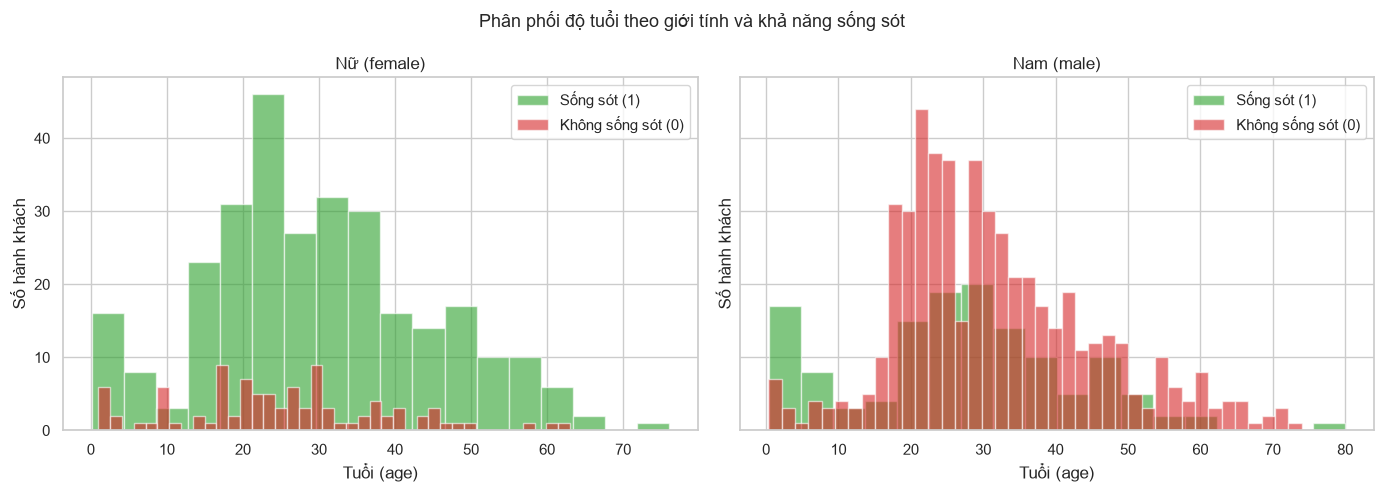

sex,Nữ (%),Nam (%)
nhom_tuoi,,
"(0, 10]",61.0,55.6
"(10, 18]",74.5,12.5
"(18, 27]",73.3,19.4
"(27, 40]",77.0,18.8
"(40, 60]",83.1,18.7
"(60, 81]",85.7,7.7


In [4]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, sex, ten in zip(axes, ["female", "male"], ["Nữ (female)", "Nam (male)"]):
    d = df[df["sex"] == sex]
    ax.hist(d.loc[d["survived"] == 1, "age"].dropna(), bins=18, alpha=0.6, color="tab:green", label="Sống sót (1)")
    ax.hist(d.loc[d["survived"] == 0, "age"].dropna(), bins=40, alpha=0.6, color="tab:red", label="Không sống sót (0)")
    ax.set_title(ten); ax.set_xlabel("Tuổi (age)"); ax.set_ylabel("Số hành khách"); ax.legend()
plt.suptitle("Phân phối độ tuổi theo giới tính và khả năng sống sót", fontsize=13)
plt.tight_layout(); plt.show()

# Tỷ lệ sống sót (%) theo nhóm tuổi và giới tính để có số liệu nhận xét
tmp = df.dropna(subset=["age"]).copy()
tmp["nhom_tuoi"] = pd.cut(tmp["age"], bins=[0, 10, 18, 27, 40, 60, 81])
bang = tmp.pivot_table(values="survived", index="nhom_tuoi", columns="sex", aggfunc="mean", observed=False)
display((bang * 100).round(1).rename(columns={"female": "Nữ (%)", "male": "Nam (%)"}))

**Nhận xét:**

- Ở **mọi nhóm tuổi**, nữ có tỷ lệ sống sót cao hơn nam rất nhiều: nữ 61.0% – 85.7%, nam chỉ 7.7% – 55.6%.
- Với trẻ em ≤ 10 tuổi, nam sống sót 55.6%, gần bằng nữ (61.0%). Điều này khớp với nguyên tắc ưu tiên "phụ nữ và trẻ em".
- Nam từ 10 – 60 tuổi chỉ sống sót 12.5% – 19.4%, nam trên 60 tuổi thấp nhất (7.7%). Trên histogram, cột "không sống sót" của nam dồn đặc ở khoảng 18 – 35 tuổi.
- Ở nữ, tỷ lệ sống sót tăng dần theo tuổi (61.0% → 85.7%). Như vậy `sex` là yếu tố quyết định mạnh nhất, còn `age` có tác động khác nhau theo từng giới.

## Câu 4: Biểu đồ khảo sát Cổng lên tàu (embarked), loại vé (pclass) với khả năng sống sót, phân biệt theo giới tính

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


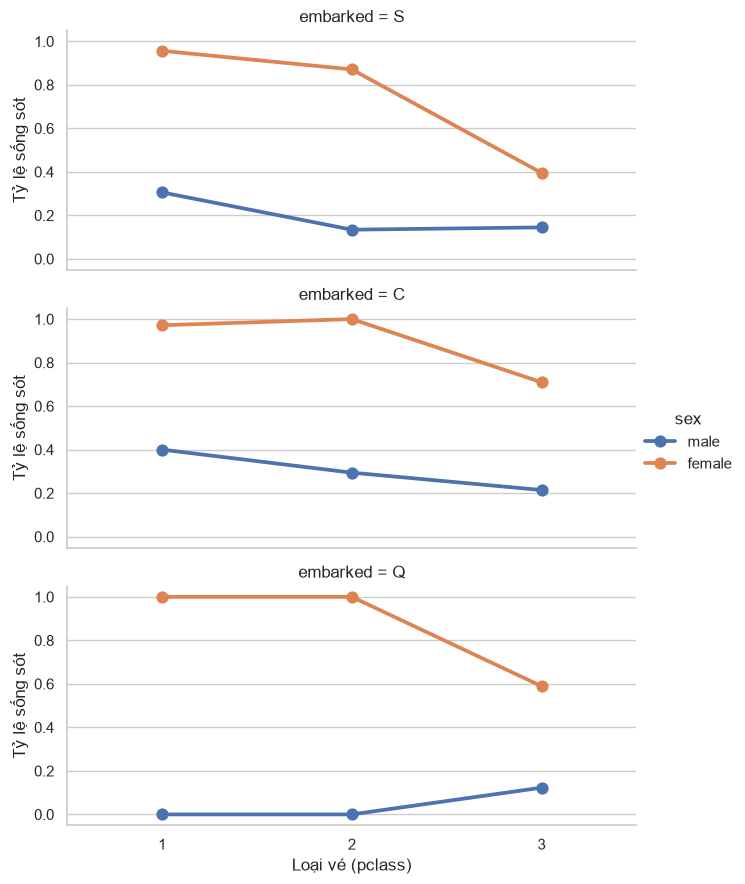

Tỷ lệ sống sót (%) theo cổng lên tàu và giới tính:


sex,female,male
embarked,,
C,90.3,30.6
Q,61.7,11.1
S,68.0,17.0


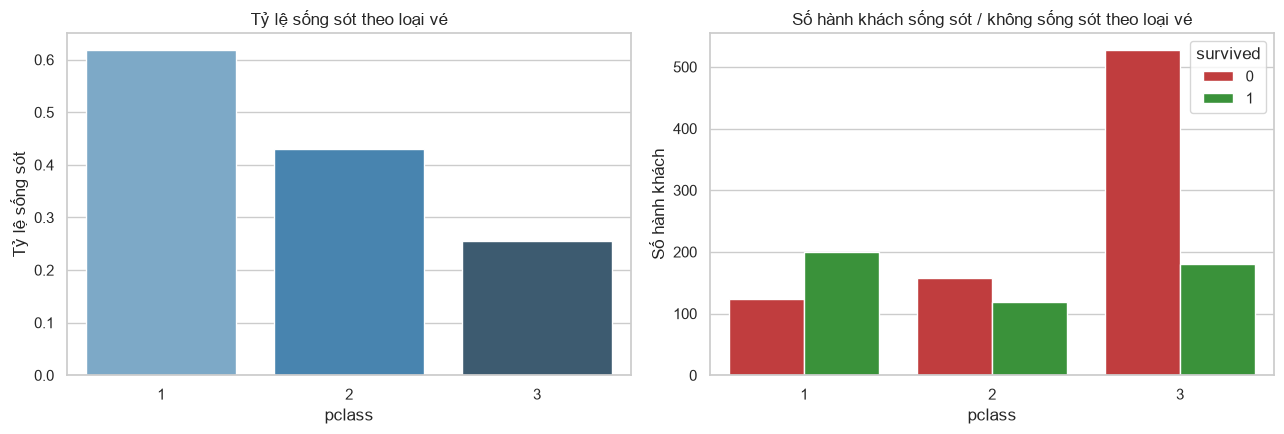

survived,0,1,All
pclass,,,
1,123,200,323
2,158,119,277
3,528,181,709
All,809,500,1309


In [5]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
g = sns.FacetGrid(df.dropna(subset=["embarked"]), row="embarked", row_order=["S", "C", "Q"], height=3, aspect=2.2)
g.map_dataframe(sns.pointplot, x="pclass", y="survived", hue="sex", order=[1, 2, 3],
                hue_order=["male", "female"], palette="deep", errorbar=None)
g.add_legend(title="sex"); g.set_axis_labels("Loại vé (pclass)", "Tỷ lệ sống sót")
plt.show()
print("Tỷ lệ sống sót (%) theo cổng lên tàu và giới tính:")
display((df.pivot_table(values="survived", index="embarked", columns="sex") * 100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(data=df, x="pclass", y="survived", ax=axes[0], errorbar=None, palette="Blues_d")
axes[0].set_title("Tỷ lệ sống sót theo loại vé"); axes[0].set_xlabel("pclass"); axes[0].set_ylabel("Tỷ lệ sống sót")
sns.countplot(data=df, x="pclass", hue="survived", ax=axes[1], palette=["tab:red", "tab:green"])
axes[1].set_title("Số hành khách sống sót / không sống sót theo loại vé"); axes[1].set_ylabel("Số hành khách")
plt.tight_layout(); plt.show()
display(pd.crosstab(df["pclass"], df["survived"], margins=True))

**Nhận xét:**

- Ở cả 3 cổng, nữ luôn sống sót nhiều hơn nam. Cổng **C** có tỷ lệ cao nhất cho cả hai giới (nữ 90.3%, nam 30.6%); cổng **Q** thấp nhất (nữ 61.7%, nam 11.1%); cổng S ở giữa (nữ 68.0%, nam 17.0%).
- Cổng lên tàu không trực tiếp quyết định việc sống sót mà phản ánh **hạng vé**: 52.2% khách lên ở C mua vé hạng 1, trong khi 91.9% khách lên ở Q là hạng 3.
- `pclass` tương quan rõ với `survived`: hạng 1 là 61.9% (200/323), hạng 2 là 43.0% (119/277), hạng 3 chỉ 25.5% (181/709). Riêng hạng 3 chiếm 528/809 = 65.3% tổng số người tử vong.
- Trên các đường pointplot, tỷ lệ sống sót giảm dần từ hạng 1 → 3 ở cả hai giới. Nữ hạng 1 – 2 gần như được cứu hết (96.5%, 88.7%), còn nữ hạng 3 chỉ 49.1%.

## Câu 5: Thống kê số người đi cùng (sibsp/parch) và khảo sát sự liên quan với thuộc tính quyết định

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Số người đi một mình       : 790
Số người đi cùng người thân: 519


relatives,0,1,2,3,4,5,6,7,10
So_hanh_khach,790,235,159,43,22,25,16,8,11


relatives,0,1,2,3,4,5,6,7,10
So_khach,790.0,235.0,159.0,43.0,22.0,25.0,16.0,8.0,11.0
Ty_le_song_sot,30.3,53.6,56.6,69.8,27.3,20.0,25.0,0.0,0.0


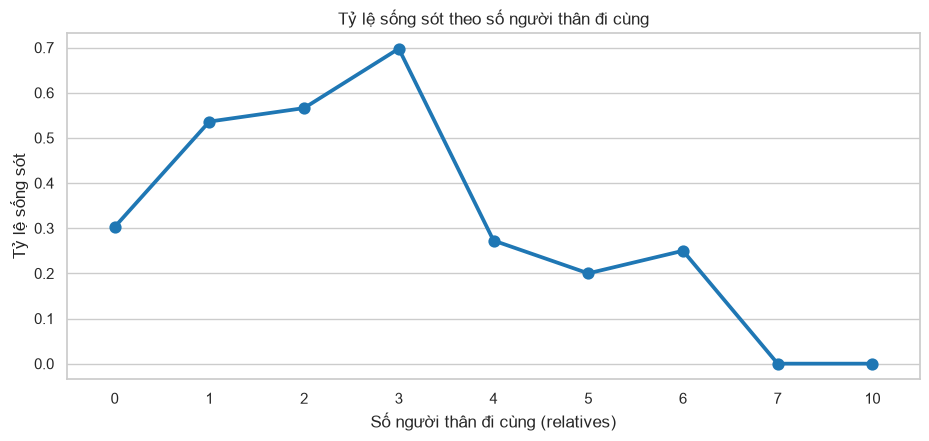

In [6]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df["relatives"] = df["sibsp"] + df["parch"]          # tổng số người thân đi cùng
df["not_alone"] = (df["relatives"] > 0).astype(int)  # 1: đi cùng người thân, 0: đi một mình
print("Số người đi một mình       :", (df["not_alone"] == 0).sum())
print("Số người đi cùng người thân:", (df["not_alone"] == 1).sum())
display(df["relatives"].value_counts().sort_index().to_frame("So_hanh_khach").T)

thongke = df.groupby("relatives")["survived"].agg(So_khach="count", Ty_le_song_sot="mean")
thongke["Ty_le_song_sot"] = (thongke["Ty_le_song_sot"] * 100).round(1)
display(thongke.T)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.pointplot(data=df, x="relatives", y="survived", errorbar=None, ax=ax, color="tab:blue")
ax.set_title("Tỷ lệ sống sót theo số người thân đi cùng"); ax.set_xlabel("Số người thân đi cùng (relatives)")
ax.set_ylabel("Tỷ lệ sống sót"); plt.show()

**Nhận xét:**

- Có **790 người đi một mình** (60.4%) và **519 người đi cùng người thân**.
- Người đi một mình chỉ sống sót 30.3%. Người có 1 – 3 người thân đi cùng có tỷ lệ cao nhất (53.6%, 56.6%, 69.8%).
- Từ 4 người thân trở lên, tỷ lệ giảm mạnh (27.3%, 20.0%, 25.0%). Các gia đình rất đông (7 hoặc 10 người thân) có tỷ lệ sống sót **0%**: gia đình lớn khó di chuyển cùng nhau và phần lớn đi vé hạng 3.
- Quan hệ giữa `relatives` và `survived` là **phi tuyến** (tăng rồi giảm). Vì vậy tạo thêm các thuộc tính `relatives` và `not_alone` là có ích.

## Câu 6: Tiền xử lý các thuộc tính thiếu dữ liệu và xoá bỏ các thuộc tính không cần thiết

In [7]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
# Giữ lại ký tự đầu của cabin (boong tàu) trước khi xoá cabin; thiếu -> 'U' (Unknown)
df["deck"] = df["cabin"].str[0].fillna("U")
display(df["deck"].value_counts().to_frame("So_khach").T)

print("Số giá trị khác nhau của ticket:", df["ticket"].nunique())
df = df.drop(columns=["body", "cabin", "boat", "home.dest", "ticket"])

# age: sinh ngẫu nhiên trong [mean - std, mean + std]
mean, std = df["age"].mean(), df["age"].std()
n_null = df["age"].isnull().sum()
print(f"age: mean = {mean:.2f}, std = {std:.2f}, số giá trị thiếu = {n_null}")
df.loc[df["age"].isnull(), "age"] = rng.integers(int(mean - std), int(mean + std), size=n_null)

# embarked: điền bằng giá trị phổ biến nhất
print("\nThông tin thuộc tính embarked:"); print(df["embarked"].describe())
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])
# fare: 1 giá trị thiếu -> điền trung vị
df["fare"] = df["fare"].fillna(df["fare"].median())

print("\nSố giá trị rỗng sau khi xử lý:")
display(df.isnull().sum().to_frame("So_gia_tri_rong").T)
print("Các thuộc tính còn lại:", list(df.columns))

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


deck,U,C,B,D,E,A,F,G,T
So_khach,1014,94,65,46,41,22,21,5,1


Số giá trị khác nhau của ticket: 929
age: mean = 29.88, std = 14.41, số giá trị thiếu = 263

Thông tin thuộc tính embarked:
count     1307
unique       3
top          S
freq       914
Name: embarked, dtype: object

Số giá trị rỗng sau khi xử lý:


,pclass,survived,name,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck
So_gia_tri_rong,0,0,0,0,0,0,0,0,0,0,0,0


Các thuộc tính còn lại: ['pclass', 'survived', 'name', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked', 'relatives', 'not_alone', 'deck']


**Nhận xét:**

- Trước khi xoá `cabin`, ký tự đầu được giữ lại thành `deck` (boong tàu). 1014 khách không có cabin được gán `U`; hai boong phổ biến nhất là C (94) và B (65).
- `ticket` có 929 giá trị khác nhau trên 1309 dòng, gần như là mã định danh nên bị xoá. Các cột `body, cabin, boat, home.dest` cũng bị xoá vì thiếu nhiều hoặc làm rò rỉ nhãn.
- 263 giá trị thiếu của `age` được điền bằng số nguyên ngẫu nhiên trong khoảng [mean − std, mean + std] = [15, 44). Cách này giữ được độ phân tán tốt hơn so với điền cùng một giá trị trung bình. Seed lấy từ MSSV nên kết quả tái lập được.
- `embarked` thiếu 2 giá trị, được điền bằng `S` (giá trị phổ biến nhất: 914/1307). `fare` thiếu 1 giá trị, được điền bằng trung vị. Sau xử lý **không còn giá trị rỗng** và còn lại 12 cột.

## Câu 7: Biến đổi các thuộc tính (fare, title, sex, embarked, nhóm tuổi, nhóm giá vé)

In [8]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
# (a) fare -> kiểu nguyên
df["fare"] = df["fare"].astype(int)

# (b) trích xuất danh hiệu (title) từ name
df["title"] = df["name"].str.extract(r" ([A-Za-z]+)\.", expand=False)
print("Các danh hiệu trích được:"); print(df["title"].value_counts().to_dict())
df["title"] = (df["title"]
               .replace(["Lady", "Countess", "Capt", "Col", "Don", "Dr", "Major", "Rev", "Sir", "Jonkheer", "Dona"], "Rare")
               .replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}))
df["title"] = df["title"].map({"Mr": 1, "Miss": 2, "Mrs": 3, "Master": 4, "Rare": 5}).fillna(0).astype(int)
df = df.drop(columns=["name"])

# (c) sex, embarked, deck -> số
df["sex"] = df["sex"].map({"male": 0, "female": 1})
df["embarked"] = df["embarked"].map({"S": 0, "C": 1, "Q": 2})
df["deck"] = df["deck"].map({c: i for i, c in enumerate("ABCDEFGTU", start=1)})

# (d) age -> 8 nhóm
df["age"] = df["age"].astype(int)
df["age_group"] = pd.cut(df["age"], bins=[-1, 11, 18, 22, 27, 33, 40, 66, 200], labels=range(1, 9)).astype(int)
print("\nSố hành khách trong mỗi nhóm tuổi:"); display(df["age_group"].value_counts().sort_index().to_frame("So_khach").T)

# (e) fare -> 6 nhóm theo các ngưỡng gợi ý
df["fare_group"] = pd.cut(df["fare"], bins=[-1, 7.91, 14.454, 31, 99, 250, np.inf], labels=range(1, 7)).astype(int)
print("Số hành khách trong mỗi nhóm giá vé:"); display(df["fare_group"].value_counts().sort_index().to_frame("So_khach").T)
print("Đối chiếu: chia 6 nhóm bằng pd.qcut (tần số bằng nhau):")
display(pd.qcut(df["fare"], 6, duplicates="drop").value_counts().sort_index().to_frame("So_khach").T)
display(df.head())

Họ tên: Phan Quốc Thắng - MSSV: 6451071073
Các danh hiệu trích được:
{'Mr': 757, 'Miss': 260, 'Mrs': 197, 'Master': 61, 'Dr': 8, 'Rev': 8, 'Col': 4, 'Major': 2, 'Mlle': 2, 'Ms': 2, 'Mme': 1, 'Capt': 1, 'Lady': 1, 'Sir': 1, 'Dona': 1, 'Jonkheer': 1, 'Countess': 1, 'Don': 1}

Số hành khách trong mỗi nhóm tuổi:


age_group,1,2,3,4,5,6,7,8
So_khach,91,149,172,220,234,190,244,9


Số hành khách trong mỗi nhóm giá vé:


fare_group,1,2,3,4,5,6
So_khach,360,313,325,227,67,17


Đối chiếu: chia 6 nhóm bằng pd.qcut (tần số bằng nhau):


fare,"(-0.001, 7.0]","(7.0, 8.0]","(8.0, 14.0]","(14.0, 26.0]","(26.0, 53.0]","(53.0, 512.0]"
So_khach,360,99,214,243,179,214


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title,age_group,fare_group
0,1,1,1,29,0,0,211,0,0,0,2,2,5,5
1,1,1,0,0,1,2,151,0,3,1,3,4,1,5
2,1,0,1,2,1,2,151,0,3,1,3,2,1,5
3,1,0,0,30,1,2,151,0,3,1,3,1,5,5
4,1,0,1,25,1,2,151,0,3,1,3,3,4,5


**Nhận xét:**

- Trích được 18 danh hiệu, phổ biến nhất là Mr (757), Miss (260), Mrs (197), Master (61). Các danh hiệu hiếm được gom vào `Rare`, Mlle/Ms đổi thành Miss, Mme đổi thành Mrs; sau đó mã hoá thành số 1 – 5.
- `sex` (0/1), `embarked` (0/1/2) và `deck` (1 – 9) được chuyển thành số. `fare` được ép về kiểu nguyên, nên phần thập phân bị cắt (7.25 → 7).
- 8 nhóm tuổi có số khách 91 / 149 / 172 / 220 / 234 / 190 / 244 / 9. Các nhóm giữa khá cân bằng, nhưng nhóm 1 (≤ 11) và nhóm 8 (> 66, chỉ 9 người) lệch. Lý do: các ngưỡng gợi ý được tính cho tập Titanic 891 dòng, và tuổi đã được điền ngẫu nhiên.
- 6 nhóm giá vé theo ngưỡng gợi ý **không cân bằng** (360 / 313 / 325 / 227 / 67 / 17) vì `fare` lệch phải. `pd.qcut` cho kết quả đều hơn (99 – 360 khách/nhóm). Nhóm đầu vẫn lớn vì sau khi ép kiểu nguyên có rất nhiều vé trùng giá 7.

## Câu 8: Tạo các thuộc tính mới: age_class và fare_per_person

In [9]:
print(f"Họ tên: {HO_TEN} - MSSV: {MSSV}")
df["age_class"] = df["age"] * df["pclass"]                                   # tuổi * loại vé
df["fare_per_person"] = (df["fare"] / (df["relatives"] + 1)).astype(int)    # giá vé / số người (làm trơn +1)
display(df[["age", "pclass", "age_class", "fare", "relatives", "fare_per_person"]].head(10))
print("Kích thước dữ liệu sau tiền xử lý:", df.shape)
display(df.head(10))
df.info()

Họ tên: Phan Quốc Thắng - MSSV: 6451071073


,age,pclass,age_class,fare,relatives,fare_per_person
0,29,1,29,211,0,211
1,0,1,0,151,3,37
2,2,1,2,151,3,37
3,30,1,30,151,3,37
4,25,1,25,151,3,37
5,48,1,48,26,0,26
6,63,1,63,77,1,38
7,39,1,39,0,0,0
8,53,1,53,51,2,17
9,71,1,71,49,0,49


Kích thước dữ liệu sau tiền xử lý: (1309, 16)


,pclass,survived,sex,age,sibsp,parch,fare,embarked,relatives,not_alone,deck,title,age_group,fare_group,age_class,fare_per_person
0,1,1,1,29,0,0,211,0,0,0,2,2,5,5,29,211
1,1,1,0,0,1,2,151,0,3,1,3,4,1,5,0,37
2,1,0,1,2,1,2,151,0,3,1,3,2,1,5,2,37
3,1,0,0,30,1,2,151,0,3,1,3,1,5,5,30,37
4,1,0,1,25,1,2,151,0,3,1,3,3,4,5,25,37
5,1,1,0,48,0,0,26,0,0,0,5,1,7,3,48,26
6,1,1,1,63,1,0,77,0,1,1,4,2,7,4,63,38
7,1,0,0,39,0,0,0,0,0,0,1,1,6,1,39,0
8,1,1,1,53,2,0,51,0,2,1,3,3,7,4,53,17
9,1,0,0,71,0,0,49,1,0,0,9,1,8,4,71,49


<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   pclass           1309 non-null   int64
 1   survived         1309 non-null   int64
 2   sex              1309 non-null   int64
 3   age              1309 non-null   int64
 4   sibsp            1309 non-null   int64
 5   parch            1309 non-null   int64
 6   fare             1309 non-null   int64
 7   embarked         1309 non-null   int64
 8   relatives        1309 non-null   int64
 9   not_alone        1309 non-null   int64
 10  deck             1309 non-null   int64
 11  title            1309 non-null   int64
 12  age_group        1309 non-null   int64
 13  fare_group       1309 non-null   int64
 14  age_class        1309 non-null   int64
 15  fare_per_person  1309 non-null   int64
dtypes: int64(16)
memory usage: 163.8 KB


**Nhận xét:**

- `age_class = age × pclass` kết hợp hai yếu tố rủi ro: khách lớn tuổi đi vé hạng thấp có giá trị lớn. Ví dụ khách 71 tuổi hạng 1 có giá trị 71, còn khách 30 tuổi hạng 3 có giá trị 90.
- `fare_per_person = fare / (relatives + 1)` cho biết giá vé thực trả cho mỗi người. Ví dụ gia đình Allison trả 151 cho 4 người, tức 37/người. Thuộc tính này phản ánh mức sống tốt hơn `fare` gốc vốn tính chung cho cả nhóm.
- Dữ liệu sau tiền xử lý gồm **1309 dòng × 16 thuộc tính, toàn bộ kiểu số nguyên, không còn giá trị thiếu**, sẵn sàng cho các thuật toán phân lớp/gom cụm.